# 05-2. Supervisor 패턴 — 작업 분배·결과 통합·평가 루프
**학습 목표:** 05-1의 Supervisor는 질문을 보고 전문 Agent 하나에게 넘긴 뒤 바로 끝났다.  
이 Notebook은 Supervisor가 ① 필요한 전문 Agent를 하나씩 호출해 결과를 모으고, ② 모인 결과가 질문에 답하기 충분한지 스스로 평가하고, ③ 부족하면 다시 Agent를 호출하는 **반복 루프**로 확장한다.  
`.env`의 `OPENAI_API_KEY`로 실제 LLM을 호출하므로 실행마다 비용이 발생한다.


## 에이전트 구성도
이 실습에서 사용하는 전체 흐름(사용자 입력 → Supervisor → 전문 Agent → 평가 → 최종 응답)은 다음과 같다.
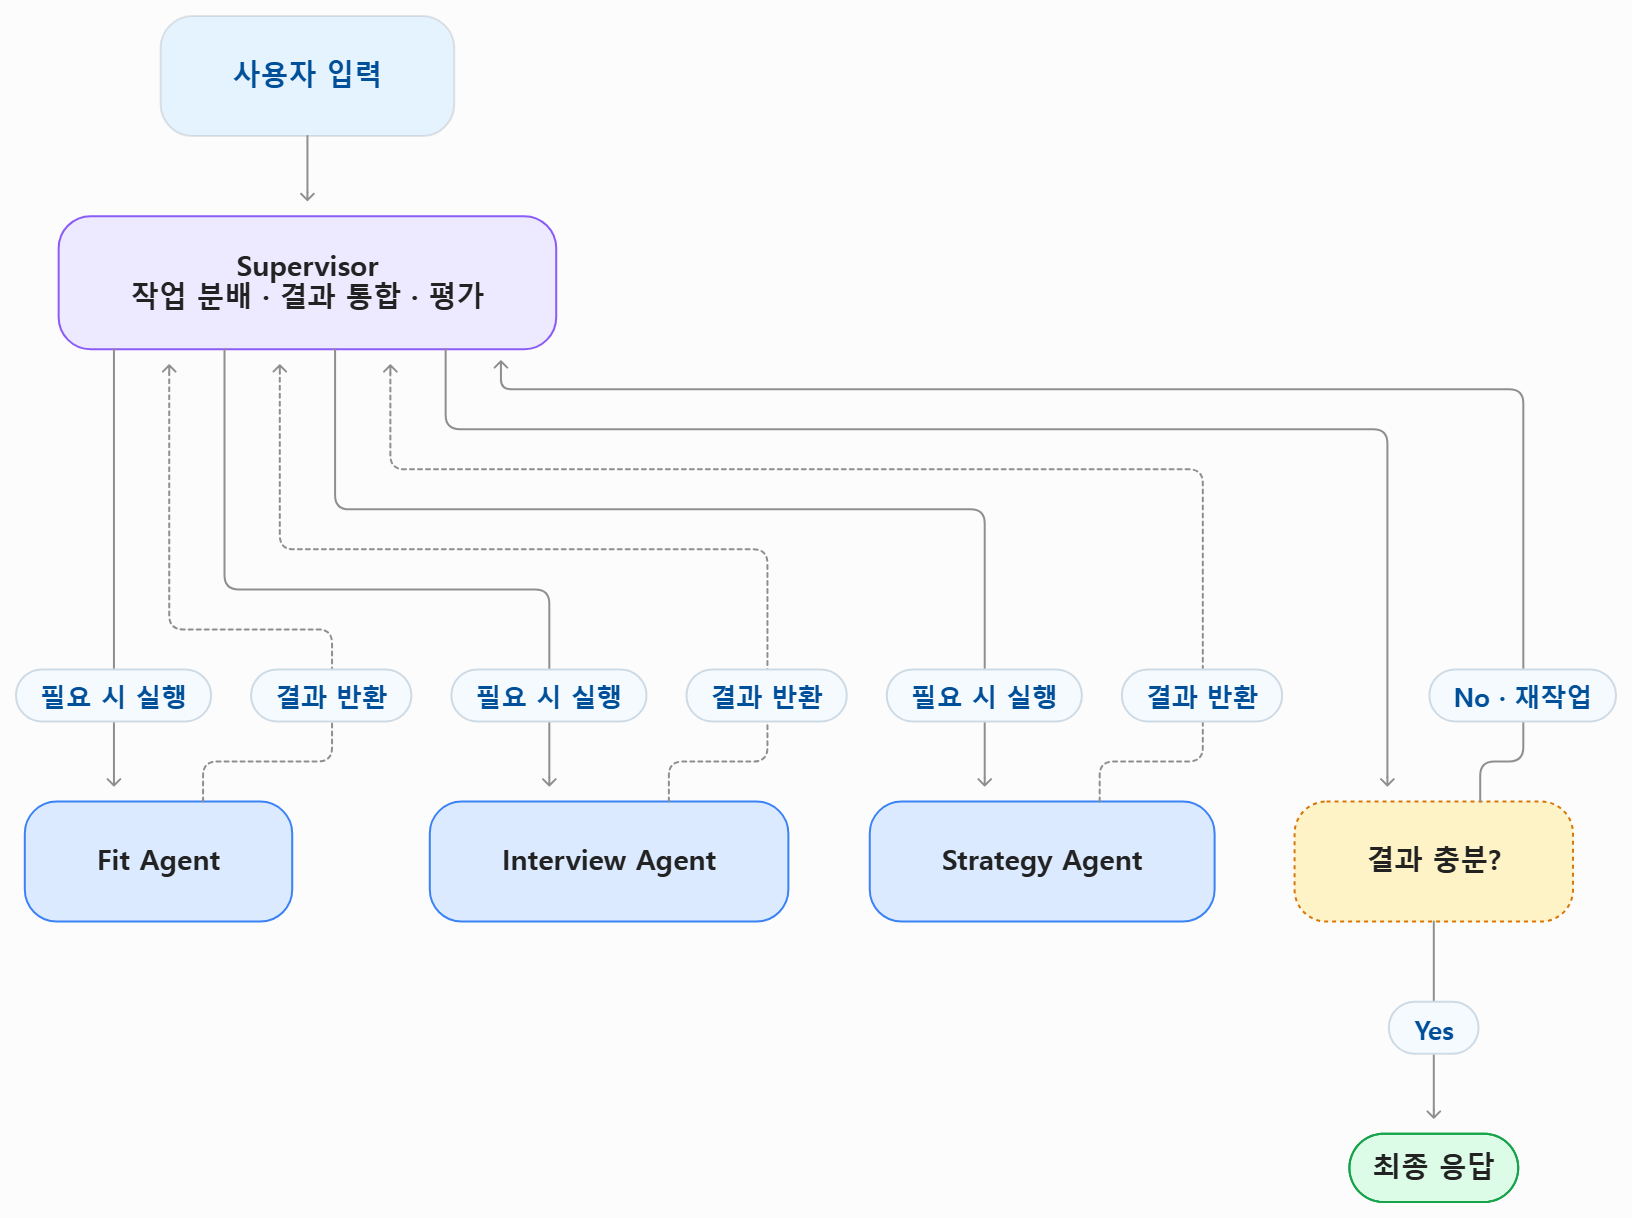

- **Supervisor**는 아직 호출하지 않은 전문 Agent 중 필요한 것을 하나 골라 실행시키고(`필요 시 실행`), Agent는 결과를 다시 Supervisor에게 돌려준다(`결과 반환`).
- 더 호출할 Agent가 없어지면 Supervisor는 평가 단계(`결과 충분?`)로 넘어간다.
- 평가 결과가 **부족**하면 다시 Supervisor로 돌아가 재작업하고(`No · 재작업`), **충분**하면 지금까지 모은 Agent 응답을 하나로 합쳐 최종 응답을 내고 끝난다(`Yes → 최종 응답`).
- `job_posting`·`candidate_resume`는 세 전문 Agent가 공통으로 참조한다.  
Supervisor(라우팅·평가)는 `llm_super`를, 전문 Agent(`fit_agent`·`interview_agent`·`strategy_agent`)는 `llm_worker`를 각각 사용한다.

`set_llm_cache(InMemoryCache())`로 인메모리 캐시를 켜두면, 똑같은 prompt로 다시 호출할 때 실제 LLM 요청 없이 캐시된 응답을 바로 돌려준다(프로세스가 살아있는 동안만 유지).

In [ ]:
from langchain_core.caches import InMemoryCache
from langchain_core.globals import set_llm_cache

# 동일한 질문(prompt)으로 다시 호출하면 실제 API 요청 없이 캐시된 응답을 재사용한다.
set_llm_cache(InMemoryCache())

## 2. Import와 LLM 설정
Supervisor의 라우팅·평가 판단에는 `common.ai_model.get_openai_model()`로 만든 `llm_super`를, 전문 Agent의 답변 생성에는 `common.ai_model.get_llm_model()`로 만든 `llm_worker`를 사용한다. 

In [ ]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph
from common.ai_model import get_llm_model, get_openai_model

# 전문 Agent 응답 생성용(llm_worker)과 Supervisor 라우팅·평가용(llm_super) LLM을 분리해서 생성한다.
llm_worker = get_llm_model()
llm_super = get_openai_model()

print(llm_worker.model_name)
print(llm_super.model_name)

In [2]:
# 응답 결과에서 <think>...</think> 블록을 제거
import re

def strip_think(text: str) -> str:
    """Qwen3 같은 추론 모델이 답변 앞에 붙이는 <think>...</think> 블록을 제거한다."""
    return re.sub(r"<think>.*?</think>", "", text, flags=re.DOTALL).strip()

## 3. 샘플 데이터
04번 미션과 같은 형태의 채용공고·이력서를 간단히 줄여서 재사용한다.  
이 Notebook의 초점은 라우팅 로직이지 역량 비교 자체가 아니므로, 전문 Agent는 이 데이터를 참고 자료로만 사용한다.


In [ ]:
# 04번 미션 데이터를 간단히 줄인 샘플 — 세 전문 Agent가 공통 참고 자료로 사용한다.
job_posting = {
    "title": "백엔드 개발자",
    "required_skills": ["Python", "SQL", "REST API"],
    "preferred_skills": ["LangGraph", "Docker"],
    "required_experience": "실무 2년 이상",
}

candidate_resume = {
    "name": "홍길동",
    "skills": ["Python", "LangGraph", "Docker"],
    "experience": "스타트업에서 1년간 백엔드 인턴 경험",
}

print(job_posting["title"], "/", candidate_resume["name"])


## 4. State 설계
05-1의 State는 `route` 하나로 "다음 Node"를 정했다.  
이번에는 Supervisor가 같은 질문에 대해 여러 번 호출되므로, "지금까지 어떤 Agent가 응답했는지"와 "평가 결과"까지 State에 남겨야 한다.

- `next_action`: Supervisor가 고른 다음 Node 이름(전문 Agent 중 하나 또는 `"evaluate"`)
- `agent_responses`: 지금까지 실행된 전문 Agent들의 응답을 모아둔 dict (키: Agent 이름)
- `supervisor_calls`: Supervisor가 몇 번 호출됐는지 — 무한 루프를 막는 안전장치로 쓴다
- `is_sufficient` / `final_response`: 평가(`evaluate`) Node가 남기는 결과


In [4]:
class SupportState(TypedDict, total=False):
    user_query: str
    job_posting: dict
    candidate_resume: dict
    next_action: str
    agent_responses: dict[str, str]
    supervisor_calls: int
    is_sufficient: bool
    final_response: str


# 전문 Agent 이름과 역할 설명. 이름을 그대로 Graph의 Node 이름으로도 쓴다.
AGENT_DESCRIPTIONS = {
    "fit_agent": "지원자 역량·자격이 채용공고 요건에 맞는지에 대한 질문",
    "interview_agent": "면접 준비, 예상 질문에 대한 질문",
    "strategy_agent": "지원 전략, 취업 방향에 대한 질문",
}
AGENT_NAMES = tuple(AGENT_DESCRIPTIONS)

# Supervisor가 이 횟수만큼 불려도 결론이 안 나면, 가진 결과만으로 강제 종료한다 (무한 루프 방지).
MAX_SUPERVISOR_CALLS = len(AGENT_NAMES) + 1
# AGENT_NAMES
MAX_SUPERVISOR_CALLS


4

## 5. Supervisor — 작업 분배
05-1의 Supervisor는 질문당 한 번만 불려서 라벨 하나를 고르고 끝났다.  
이번 Supervisor는 **같은 질문에 대해 여러 번 호출될 수 있다** — 아직 응답을 받지 못한 Agent 중 필요한 것을 하나 고르고, 더 고를 Agent가 없으면 평가(`evaluate`)로 넘긴다.


In [5]:

def supervisor(state: SupportState) -> dict:
    """아직 호출하지 않은 Agent 중 필요한 것을 고른다. 더 고를 Agent가 없으면 평가 단계로 보낸다."""
    agent_responses = state.get("agent_responses", {})
    remaining_agents = [name for name in AGENT_NAMES if name not in agent_responses]
    calls_so_far = state.get("supervisor_calls", 0) + 1

    # 더 호출할 Agent가 없거나, 반복이 너무 길어지면 바로 평가로 넘긴다.
    if not remaining_agents or calls_so_far > MAX_SUPERVISOR_CALLS:
        return {"next_action": "evaluate", "supervisor_calls": calls_so_far}

    prompt = (
        "아래 질문에 답하기 위해 지금 추가로 실행이 필요한 담당자를 정확히 하나만, 다른 말 없이 라벨로만 답하라.\n"
        "이미 답변을 받은 담당자는 다시 고르지 마라. 더 이상 필요한 담당자가 없으면 'evaluate'라고만 답하라.\n"
        + "\n".join(f"{name}: {AGENT_DESCRIPTIONS[name]}" for name in remaining_agents) + "\n"
        f"라벨은 반드시 {remaining_agents + ['evaluate']} 중 하나.\n질문: {state['user_query']}"
    )
    label = strip_think(llm_super.invoke(prompt).content)
    next_action = label if label in remaining_agents else "evaluate"
    return {"next_action": next_action, "supervisor_calls": calls_so_far}


def route_after_supervisor(state: SupportState) -> str:
    """add_conditional_edges가 호출하는 판단 함수. supervisor가 쓴 next_action을 그대로 다음 Node 이름으로 쓴다."""
    return state["next_action"]

## 6. 전문 Agent 세 개
각 Agent는 자신의 답변을 `agent_responses` dict에 자기 이름으로 추가하고, 결과를 Supervisor에게 돌려준다(`add_edge(이름, "supervisor")`).  
05-1처럼 바로 END로 가지 않는 점이 다르다.  
세 Agent는 역할 설명만 다르고 나머지 로직은 같으므로, 공통 로직을 `_run_agent`로 묶어 중복을 없앤다.


In [6]:
def _run_agent(state: SupportState, name: str, role_description: str) -> dict:
    """세 Agent가 공통으로 쓰는 실행 로직. 역할 설명만 다르고 나머지는 동일하다."""
    prompt = (
        f"당신은 {role_description}. 채용공고와 이력서를 참고해 질문에 답하라. "
        "공고·이력서에 없는 내용은 추측하지 마라.\n"
        f"채용공고: {state['job_posting']}\n이력서: {state['candidate_resume']}\n"
        f"질문: {state['user_query']}"
    )
    response = strip_think(llm_worker.invoke(prompt).content)
    agent_responses = {**state.get("agent_responses", {}), name: response}
    return {"agent_responses": agent_responses}


def fit_agent(state: SupportState) -> dict:
    """역량·자격 비교 질문에 답한다."""
    return _run_agent(state, "fit_agent", "채용공고 요건과 지원자 보유 역량을 비교하는 역량 비교 담당자다")


def interview_agent(state: SupportState) -> dict:
    """면접 준비 질문에 답한다."""
    return _run_agent(state, "interview_agent", "예상 질문과 답변 방향을 제시하는 면접 코치다")


def strategy_agent(state: SupportState) -> dict:
    """지원 전략 질문에 답한다."""
    return _run_agent(state, "strategy_agent", "지원자의 강점과 공고 요건을 고려해 지원 전략을 제시하는 취업 전략 어드바이저다")

## 7. 평가 — 결과가 충분한가
모든 전문 Agent가 응답을 마치면(혹은 Supervisor 호출 횟수가 한계에 도달하면) `evaluate` Node가 모인 응답으로 질문에 답하기 충분한지 판단한다.   
충분하면 응답들을 하나의 최종 답변으로 합치고, 부족하면 다시 Supervisor로 돌려보내 재작업시킨다.  


In [7]:
def evaluate(state: SupportState) -> dict:
    """모인 Agent 응답이 질문에 답하기 충분한지 판단하고, 충분하면 최종 응답까지 합성한다."""
    responses = state.get("agent_responses", {})
    combined = "\n\n".join(f"[{name}]\n{text}" for name, text in responses.items())

    # 모든 Agent를 다 썼거나 반복 한계에 도달했으면, LLM에게 묻지 않고 그대로 충분하다고 간주한다.
    exhausted = len(responses) >= len(AGENT_NAMES) or state.get("supervisor_calls", 0) >= MAX_SUPERVISOR_CALLS
    if exhausted:
        is_sufficient = True
    else:
        response = llm_super.invoke(
                    "아래는 사용자 질문과 지금까지 모은 담당자별 답변이다. "
                    "이 답변들만으로 질문에 충분히 답할 수 있으면 '충분', 아니면 '부족'이라고만 답하라.\n"
                    f"질문: {state['user_query']}\n{combined}"
                ).content
        verdict = strip_think(response)
        is_sufficient = verdict.startswith("충분")

    if not is_sufficient:
        return {"is_sufficient": False}

    response = llm_super.invoke(
            "아래 담당자별 답변을 사용자 질문에 대한 하나의 최종 답변으로 자연스럽게 통합하라. "
            "중복은 제거하고, 질문과 관련 없는 내용은 빼라.\n"
            f"질문: {state['user_query']}\n{combined}"
        ).content
    final_response = strip_think(response)
    return {"is_sufficient": True, "final_response": final_response}


def route_after_evaluate(state: SupportState) -> str:
    """결과가 충분하면 Graph를 끝내고, 부족하면 Supervisor로 돌아가 재작업한다."""
    return END if state["is_sufficient"] else "supervisor"

## 8. Graph 구성 — 루프가 있는 Graph
05-1은 Supervisor에서 전문 Agent로 가면 바로 END였다.   
이번에는 전문 Agent가 다시 Supervisor로 돌아오고(`add_edge(이름, "supervisor")`), 평가 결과가 부족하면 평가 Node에서도 다시 Supervisor로 돌아온다.   
Graph에 **사이클(cycle)**이 생기는 점이 05-1과 가장 큰 차이다.


In [8]:
builder = StateGraph(SupportState)
builder.add_node("supervisor", supervisor)
builder.add_node("fit_agent", fit_agent)
builder.add_node("interview_agent", interview_agent)
builder.add_node("strategy_agent", strategy_agent)
builder.add_node("evaluate", evaluate)

builder.add_edge(START, "supervisor")
# Supervisor는 전문 Agent 중 하나 또는 evaluate로 분기한다.
builder.add_conditional_edges(
    "supervisor",
    route_after_supervisor,
    {**{name: name for name in AGENT_NAMES}, "evaluate": "evaluate"},
)
# 전문 Agent는 결과를 Supervisor에게 돌려준다 — 05-1과 달리 END로 바로 가지 않는다.
for name in AGENT_NAMES:
    builder.add_edge(name, "supervisor")
# 평가가 부족하면 Supervisor로 돌아가 재작업하고(사이클), 충분하면 Graph가 끝난다.
builder.add_conditional_edges("evaluate", route_after_evaluate, {"supervisor": "supervisor", END: END})
graph = builder.compile()


## 9. Graph 시각화
Supervisor ↔ 전문 Agent, Supervisor ↔ evaluate 사이를 오가는 순환 Edge가 시각화에 그대로 나타난다.


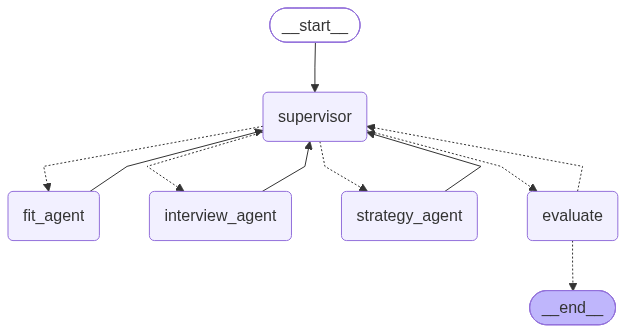

In [9]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    # 시각화 서비스가 없어도 Graph의 실행은 계속된다.
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())


## 10. 실행과 평가 루프 검증
한 전문 Agent만으로 충분한 질문과, 두 Agent의 답변을 모아야 하는 질문을 각각 넣어 Supervisor가 몇 개의 Agent를 호출했는지, 평가가 언제 멈췄는지 확인한다.  
질문마다 Supervisor·evaluate가 여러 번 호출될 수 있어 05-1보다 LLM 호출 횟수(=비용)가 더 들쭉날쭉하다.


In [ ]:
# 첫 번째 질문은 Agent 하나로 끝날 수도 있고, 두 번째 질문은 역량 비교 + 면접 준비처럼
# 여러 Agent의 답변을 모아야 한다 — Supervisor가 루프를 몇 번 도는지 비교해본다.
test_cases = [
    "SQL 역량이 부족한데 이 공고에 지원할 수 있을까요?",
    "제 역량이 이 공고에 맞는지 확인하고, 맞다면 면접 준비는 어떻게 해야 할까요?",
]

for query in test_cases:
    state = {"user_query": query, "job_posting": job_posting, "candidate_resume": candidate_resume}
    result = graph.invoke(state)
    print(f"질문: {query}")
    print(f"호출된 Agent: {list(result['agent_responses'])}")
    print(f"평가: {'충분' if result['is_sufficient'] else '부족(강제 종료)'}")
    print(result["final_response"], "...\n")
    print("-"*50)


## 11. 핵심 개념 정리와 수강생 미션
05-1의 `add_conditional_edges`는 "다음 Node가 무엇인가"만 실행 중에 정했다.  
05-2는 거기에 **사이클**을 더해, Supervisor가 "① 필요한 Agent 호출 → ② 결과 통합 → ③ 충분한지 평가"를 스스로 반복하게 만든다.  
이런 루프는 멈추는 조건이 명확하지 않으면 끝나지 않으므로, `evaluate`의 `exhausted` 체크와 `MAX_SUPERVISOR_CALLS`처럼 **반드시 종료를 보장하는 안전장치**가 함께 있어야 한다.

**미션:** `evaluate`가 "부족"이라고 판단했을 때 그 이유(무엇이 더 필요한지)도 함께 반환하도록 수정하고, 그 이유를 Supervisor의 다음 프롬프트에 포함시켜 재작업 품질을 높여라.  
State에 `missing_info`와 같은 Key가 필요한지 먼저 판단하고, `evaluate`·`supervisor` 두 함수를 모두 수정하라.
